# Do Wikipedia's budget and gross agree with a second source?

Every profit number in this project is parsed from Wikipedia infoboxes. A parser can misread a currency, a range
or a rentals figure, so we check the figures against a second source: TMDB's `budget` and `revenue` for the same
films, matched on IMDb ID.

This notebook reads the saved output of `scripts/imdb/tmdb_compare.py` and needs no raw data. It shows counts,
rates and distributions only; TMDB's per-film figures stay in `data/raw`, because this repo is public.

**What the check captures.** Whether two sources report about the same dollar figure for a film.

**What it misses.** TMDB is edited by users without citations, and both sources can copy the same wrong number.
Agreement isn't proof, and a disagreement doesn't say which side is wrong.

**Two assumptions.** TMDB has no currency field, so we read its figures as US dollars. And TMDB stores 0 when it
has no figure, so a 0 counts as missing, never as a zero budget.

All films here pass the clean rule in `analysis/clean_rule.py`, except in section 6, which looks at the films
the rule drops.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

REPO = Path.cwd().resolve().parent   # notebooks -> repo root
res = json.loads((REPO / "analysis" / "checks" / "tmdb_compare.json").read_text())
T = res["tiers"]
a = T["all clean"]
pct = lambda x: f"{100 * x:.1f}%"

display(Markdown(
    f"**Takeaway.** On the {res['clean_movies']:,} clean movies (TMDB snapshot of {res['tmdb_snapshot']}), "
    f"{res['matched_to_tmdb_row']:,} have a TMDB row. TMDB's budget is within 10% of Wikipedia's for "
    f"{pct(a['budget']['within_10pct'])} of the {a['budget']['n']:,} movies where it has one, and its revenue is "
    f"within 10% of Wikipedia's gross for {pct(a['gross']['within_10pct'])} of {a['gross']['n']:,}. Where TMDB has "
    f"both figures ({a['both_tmdb_fields']:,} movies), the two sources agree on whether the film grossed under its "
    f"budget for {pct(a['same_under_budget_call'])}, and log(gross / budget) correlates at "
    f"{a['spearman_log_multiple']:.3f} (Spearman).\n\n"
    f"Three things temper that. The sources aren't independent: {pct(a['budget']['exactly_equal'])} of TMDB budgets "
    f"are the very same number as Wikipedia's, so the agreement mostly shows that the parser read Wikipedia "
    f"correctly, not that Wikipedia is right. {a['flips']['flips']} films change their under-budget label between "
    f"the sources, and {a['flips']['flips_elsewhere']} of those aren't near break-even. And the check only covers "
    f"films already in the clean sample: of the {res['all_movies'] - res['clean_movies']:,} films outside it, "
    f"{sum(r['tmdb_has_both'] for r in res['outside_clean']):,} have both figures on TMDB."))

**Takeaway.** On the 6,413 clean movies (TMDB snapshot of 2026-11-15), 6,413 have a TMDB row. TMDB's budget is within 10% of Wikipedia's for 83.2% of the 6,014 movies where it has one, and its revenue is within 10% of Wikipedia's gross for 85.4% of 6,131. Where TMDB has both figures (5,890 movies), the two sources agree on whether the film grossed under its budget for 96.1%, and log(gross / budget) correlates at 0.959 (Spearman).

Three things temper that. The sources aren't independent: 71.9% of TMDB budgets are the very same number as Wikipedia's, so the agreement mostly shows that the parser read Wikipedia correctly, not that Wikipedia is right. 231 films change their under-budget label between the sources, and 134 of those aren't near break-even. And the check only covers films already in the clean sample: of the 6,260 films outside it, 2,133 have both figures on TMDB.

## 1. How often do the two sources agree?

One row per money field and vote tier. A movie counts only if TMDB has a figure for that field (TMDB stores 0
when it has none). "Within 10%" means the TMDB figure is within 10% of the Wikipedia one.

In [2]:
rows = []
for tier, s in T.items():
    for field in ("budget", "gross"):
        f = s[field]
        rows.append({"tier": tier, "field": field, "clean movies": s["n"], "TMDB has a figure": f["n"],
                     "TMDB has none": f["tmdb_missing"], "within 1%": pct(f["within_1pct"]),
                     "within 10%": pct(f["within_10pct"]), "within 25%": pct(f["within_25pct"]),
                     "off by 2x or more": pct(f["off_by_2x_or_more"]), "Spearman (logs)": f["spearman_log"]})
agree = pd.DataFrame(rows)
agree

,tier,field,clean movies,TMDB has a figure,TMDB has none,within 1%,within 10%,within 25%,off by 2x or more,Spearman (logs)
0,all clean,budget,6413,6014,399,72.5%,83.2%,92.3%,2.5%,0.9849
1,all clean,gross,6413,6131,282,69.8%,85.4%,90.3%,4.6%,0.9867
2,100k+,budget,2352,2348,4,70.9%,85.5%,95.4%,1.1%,0.9918
3,100k+,gross,2352,2346,6,78.5%,92.7%,95.5%,1.7%,0.9945
4,10k-100k,budget,4061,3666,395,73.6%,81.8%,90.3%,3.5%,0.9746
5,10k-100k,gross,4061,3785,276,64.5%,80.9%,87.1%,6.4%,0.9703


## 2. Where do they disagree, and in which direction?

Each bar counts movies by log10(TMDB / Wikipedia). Zero means the two figures match, +1 means TMDB is ten times
higher and -1 ten times lower. The y-axis is logarithmic, because the bar at zero would otherwise hide
everything else. Ratios beyond 100x are counted in the end bars.

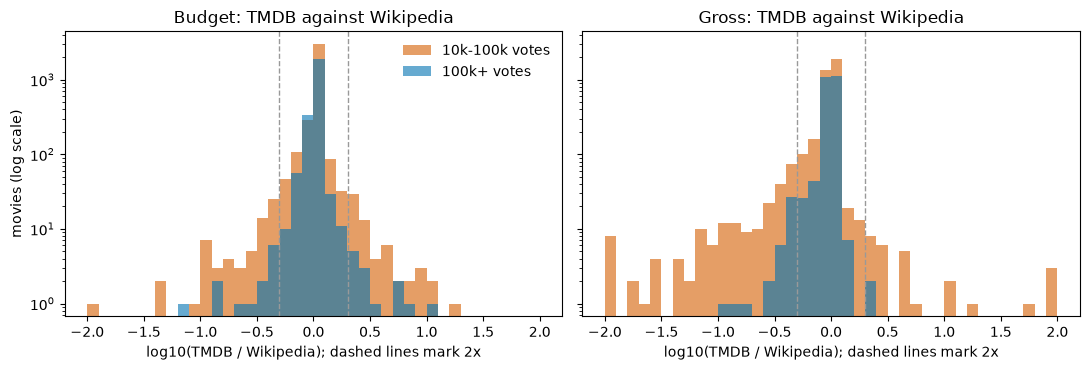

,tier,field,TMDB at least 2x higher,TMDB at most half
0,all clean,budget,75,77
1,all clean,gross,29,252
2,100k+,budget,13,12
3,100k+,gross,2,38
4,10k-100k,budget,62,65
5,10k-100k,gross,27,214


In [3]:
edges = np.array(res["ratio_hist_edges_log10"])
mid, width = (edges[:-1] + edges[1:]) / 2, np.diff(edges)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, field, label in zip(axes, ("budget", "gross"), ("Budget", "Gross")):
    for tier, colour in (("10k-100k", "#D55E00"), ("100k+", "#0072B2")):
        ax.bar(mid, T[tier][field]["ratio_hist"], width=width, color=colour, alpha=.6, label=f"{tier} votes")
    ax.axvline(np.log10(2), color="#999999", ls="--", lw=1)
    ax.axvline(-np.log10(2), color="#999999", ls="--", lw=1)
    ax.set_yscale("log")
    ax.set_title(f"{label}: TMDB against Wikipedia")
    ax.set_xlabel("log10(TMDB / Wikipedia); dashed lines mark 2x")
axes[0].set_ylabel("movies (log scale)")
axes[0].legend(frameon=False)
plt.tight_layout()
plt.show()

direction = pd.DataFrame([{"tier": tier, "field": field, "TMDB at least 2x higher": s[field]["tmdb_higher_2x"],
                           "TMDB at most half": s[field]["tmdb_lower_2x"]}
                          for tier, s in T.items() for field in ("budget", "gross")])
direction

In [4]:
g = a["gross"]
display(Markdown(
    f"Budgets disagree in both directions about equally ({a['budget']['tmdb_higher_2x']} higher, "
    f"{a['budget']['tmdb_lower_2x']} lower). Gross doesn't: when the two differ by 2x or more, TMDB is the lower one "
    f"{g['tmdb_lower_2x']} times against {g['tmdb_higher_2x']}. {res['tmdb_revenue_under_1000']} TMDB revenues are "
    f"under $1,000, which looks like a figure typed in millions.".replace("$", "\\$")))

Budgets disagree in both directions about equally (75 higher, 77 lower). Gross doesn't: when the two differ by 2x or more, TMDB is the lower one 252 times against 29. 4 TMDB revenues are under \$1,000, which looks like a figure typed in millions.

## 3. Does the disagreement change who counts as a flop?

The analyses use gross ÷ budget, and several split films into those that grossed under their budget and the
rest. This table uses only movies where TMDB has both figures.

In [5]:
flops = pd.DataFrame([{"tier": tier, "movies with both TMDB figures": s["both_tmdb_fields"],
                       "under budget (Wikipedia)": s["under_budget_wikipedia"],
                       "under budget (TMDB)": s["under_budget_tmdb"],
                       "same call": pct(s["same_under_budget_call"]),
                       "Spearman of log(gross / budget)": s["spearman_log_multiple"]} for tier, s in T.items()])
flops

,tier,movies with both TMDB figures,under budget (Wikipedia),under budget (TMDB),same call,Spearman of log(gross / budget)
0,all clean,5890,1532,1631,96.1%,0.9593
1,100k+,2343,165,180,98.5%,0.9701
2,10k-100k,3547,1367,1451,94.5%,0.9419


## 4. Are these two sources, or one source copied?

If TMDB's editors took their figures from Wikipedia (or both took them from the same place), agreement tells us
the parser read the infobox correctly and nothing about whether the figure is true. "Exactly equal" means the
same number to the dollar. Wikipedia usually rounds gross to three digits, so for gross we also count figures
within 0.5% of each other.

In [6]:
same = pd.DataFrame([{"tier": tier, "field": field, "TMDB has a figure": s[field]["n"],
                      "exactly equal": pct(s[field]["exactly_equal"]),
                      "within 0.5%": pct(s[field]["identical_within_half_pct"]),
                      "within 10%": pct(s[field]["within_10pct"])}
                     for tier, s in T.items() for field in ("budget", "gross")])
display(same)
b, g = a["budget"], a["gross"]
display(Markdown(
    f"Most of the agreement is identity. Of the budgets within 10%, "
    f"{pct(b['exactly_equal'] / b['within_10pct'])} are exactly equal; of the grosses within 10%, "
    f"{pct(g['identical_within_half_pct'] / g['within_10pct'])} are within 0.5%. Read the agreement rate as a check "
    f"on the parser. The part that works as a second opinion is the remainder, where the sources differ."))

,tier,field,TMDB has a figure,exactly equal,within 0.5%,within 10%
0,all clean,budget,6014,71.9%,72.1%,83.2%
1,all clean,gross,6131,13.1%,63.7%,85.4%
2,100k+,budget,2348,70.1%,70.4%,85.5%
3,100k+,gross,2346,9.6%,73.0%,92.7%
4,10k-100k,budget,3666,73.0%,73.2%,81.8%
5,10k-100k,gross,3785,15.3%,58.0%,80.9%


Most of the agreement is identity. Of the budgets within 10%, 86.3% are exactly equal; of the grosses within 10%, 74.6% are within 0.5%. Read the agreement rate as a check on the parser. The part that works as a second opinion is the remainder, where the sources differ.

## 5. Which films change their flop label?

A film near break-even can flip on a small difference, and that's expected. A flip far from break-even means the
two sources disagree a lot about that film. "Near break-even" is a Wikipedia gross ÷ budget between 0.8 and
1.25.

In [7]:
flip = pd.DataFrame([{"tier": tier, "films with both TMDB figures": s["both_tmdb_fields"],
                      "label flips": s["flips"]["flips"],
                      "flips near break-even": s["flips"]["flips_near_break_even"],
                      "flips elsewhere": s["flips"]["flips_elsewhere"],
                      "flop on Wikipedia only": s["flips"]["flop_on_wikipedia_only"],
                      "flop on TMDB only": s["flips"]["flop_on_tmdb_only"]} for tier, s in T.items()])
display(flip)
f = a["flips"]
display(Markdown(
    f"{f['flips']} films flip, {pct(f['flips'] / a['both_tmdb_fields'])} of those with both TMDB figures. "
    f"{f['flips_near_break_even']} are near break-even and {f['flips_elsewhere']} aren't. The flips lean one way: "
    f"{f['flop_on_tmdb_only']} films are flops only on TMDB against {f['flop_on_wikipedia_only']} only on "
    f"Wikipedia, which fits section 2, where TMDB's gross is the lower one far more often. We haven't rerun any "
    f"downstream result with TMDB's figures, so we can't yet say whether these flips move a finding."))

,tier,films with both TMDB figures,label flips,flips near break-even,flips elsewhere,flop on Wikipedia only,flop on TMDB only
0,all clean,5890,231,97,134,66,165
1,100k+,2343,35,23,12,10,25
2,10k-100k,3547,196,74,122,56,140


231 films flip, 3.9% of those with both TMDB figures. 97 are near break-even and 134 aren't. The flips lean one way: 165 films are flops only on TMDB against 66 only on Wikipedia, which fits section 2, where TMDB's gross is the lower one far more often. We haven't rerun any downstream result with TMDB's figures, so we can't yet say whether these flips move a finding.

## 6. What about the films the clean rule drops?

Sections 1 to 5 only test films that passed the clean rule. But a parser failure usually pushes a film out of
the sample: no figure parsed, or a currency read as non-dollar. This table takes every film the rule drops, by
the first reason that applies, and counts how many have both figures on TMDB.

In [8]:
out = pd.DataFrame(res["outside_clean"]).rename(columns={
    "reason": "why it isn't clean", "films": "films", "tmdb_has_both": "TMDB has both figures",
    "tmdb_has_both_100k": "of which 100k+", "tmdb_has_both_10k_100k": "of which 10k-100k"})
display(out)
r0 = res["outside_clean"][0]
display(Markdown(
    f"The largest group is *{r0['reason']}*: {r0['films']:,} films, and TMDB has both figures for "
    f"{r0['tmdb_has_both']:,} of them. Those are the films to read next. Either the infobox has a figure the parser "
    f"missed, or Wikipedia has none and TMDB could fill the gap, if we decide its figures are good enough. Films "
    f"dropped for a non-dollar currency or a rentals flag are different: there TMDB's figure may be the same "
    f"non-comparable number, so it can't simply replace Wikipedia's."))

,why it isn't clean,films,TMDB has both figures,of which 100k+,of which 10k-100k
0,no budget or gross parsed,4231,740,55,685
1,budget or gross not in USD,944,523,52,471
2,"gross flagged rentals, regional or direct-to-v...",514,394,57,337
3,released before 1975 or after 2025,455,388,104,284
4,streaming distributor,109,86,42,44
5,"budget or gross under $1,000",7,2,0,2


The largest group is *no budget or gross parsed*: 4,231 films, and TMDB has both figures for 740 of them. Those are the films to read next. Either the infobox has a figure the parser missed, or Wikipedia has none and TMDB could fill the gap, if we decide its figures are good enough. Films dropped for a non-dollar currency or a rentals flag are different: there TMDB's figure may be the same non-comparable number, so it can't simply replace Wikipedia's.

## 7. Why do those films have no Wikipedia figure?

Take the films from section 6 that have no parsed budget or gross but both figures on TMDB, and ask where the
figure went missing. Only the last group can hold parser misses.

In [9]:
un = pd.DataFrame(res["unparsed_with_tmdb"]).rename(columns={
    "group": "where it went missing", "films": "films", "missing_budget": "budget missing",
    "missing_gross": "gross missing", "missing_both": "both missing", "tier_100k": "100k+ votes"})
un

,where it went missing,films,budget missing,gross missing,both missing,100k+ votes
0,no Wikipedia article linked,8,0,0,8,2
1,article has no infobox,2,0,0,2,0
2,no infobox field for the missing figure,657,489,86,82,45
3,"raw value present, no number parsed",73,39,12,22,8


In [10]:
U = {r["group"]: r for r in res["unparsed_with_tmdb"]}
L = res["unparsed_sample_labels"]["categories"]
chk = res["no_field_wikitext_check"]
display(Markdown(
    f"**Possible parser misses.** A seeded random 30 of the {U['raw value present, no number parsed']['films']} films "
    f"with a raw value but no number (`tmdb_compare.py --sample-unparsed`) were labelled from their raw infobox values "
    f"by the coding agent, not by a group member; the labels are in `analysis/checks/tmdb_unparsed_labels.csv`. "
    f"{L.get('non_usd', 0)} hold a non-dollar amount the parser can't read (currency templates such as `{{{{JP¥|…}}}}`, "
    f"currency names, a `link=yes` left in front of a rupee figure), {L.get('no_money_figure', 0)} hold no money "
    f"figure (French admissions, \"Debated\", a number with no currency) and {L.get('usd_missed', 0)} are dollar "
    f"figures the parser missed: a lower bound (\"\\$>25 million\") and a gross computed by a conversion "
    f"template. Non-dollar figures would be dropped by the clean rule anyway, so parser misses barely touch the "
    f"clean sample.\n\n"
    f"**No figure on Wikipedia.** For {U['no infobox field for the missing figure']['films']} films "
    f"({U['no infobox field for the missing figure']['tier_100k']} of them 100k+) the infobox has no field for the "
    f"missing figure, mostly the budget, and TMDB has one. A plain search of the article wikitext, independent of the "
    f"parser, finds a non-empty line for the missing figure in {chk['nonempty_line_for_missing_figure']} of "
    f"{chk['films']}. Filling these from TMDB would add films, mostly to the 10k to 100k tier, which has the most "
    f"flops. That's a decision about TMDB's quality and terms for the group, not something this check settles.\n\n"
    f"**A linking bug.** *Horizon: An American Saga – Chapter 1* is linked to two Wikipedia articles, and the pipeline "
    f"keeps the franchise article (a budget for two films, no gross), so the film drops out. It's one film today."))

**Possible parser misses.** A seeded random 30 of the 73 films with a raw value but no number (`tmdb_compare.py --sample-unparsed`) were labelled from their raw infobox values by the coding agent, not by a group member; the labels are in `analysis/checks/tmdb_unparsed_labels.csv`. 24 hold a non-dollar amount the parser can't read (currency templates such as `{{JP¥|…}}`, currency names, a `link=yes` left in front of a rupee figure), 4 hold no money figure (French admissions, "Debated", a number with no currency) and 2 are dollar figures the parser missed: a lower bound ("\$>25 million") and a gross computed by a conversion template. Non-dollar figures would be dropped by the clean rule anyway, so parser misses barely touch the clean sample.

**No figure on Wikipedia.** For 657 films (45 of them 100k+) the infobox has no field for the missing figure, mostly the budget, and TMDB has one. A plain search of the article wikitext, independent of the parser, finds a non-empty line for the missing figure in 1 of 657. Filling these from TMDB would add films, mostly to the 10k to 100k tier, which has the most flops. That's a decision about TMDB's quality and terms for the group, not something this check settles.

**A linking bug.** *Horizon: An American Saga – Chapter 1* is linked to two Wikipedia articles, and the pipeline keeps the franchise article (a budget for two films, no gross), so the film drops out. It's one film today.

## 8. Do the results change with TMDB's money?

`scripts/imdb/tmdb_robustness.py` reruns three headlines with each analysis's own code. It first reproduces the
committed number exactly, then runs twice on the films where TMDB has both figures: once with Wikipedia's money
and once with TMDB's. TMDB's figures replace Wikipedia's everywhere money enters: the outcome, the budget control,
and the hit and flop cut-offs. Comparing those two runs isolates the money source.

In [11]:
rb = json.loads((REPO / "analysis" / "checks" / "tmdb_robustness.json").read_text())
A, S = rb["arcs_step7"], rb["scripts_and_reviews"]
rows = []
for k, label in (("D1", "arcs D1 (swing)"), ("D2", "arcs D2 (ending lift)")):
    rows.append({"result": label, **{f"{v}": f"{A[k][v]['rho']:+.3f} (p {A[k][v]['p']:.3f}, n {A[k][v]['n']})"
                                     for v in ("reproduce", "wikipedia", "tmdb")}})
for f in ("degree centralisation", "network density", "clustering", "lead's share of lines"):
    rows.append({"result": f"script: {f}", **{v: f"{S[v]['features'][f]['rho']:+.3f} (q {S[v]['features'][f]['q_partial']:.3f})"
                                              for v in ("reproduce", "wikipedia", "tmdb")}})
rows.append({"result": "script features with q < 0.05", **{v: f"{S[v]['features_q_partial_below_005']} of 15"
                                                          for v in ("reproduce", "wikipedia", "tmdb")}})
rows.append({"result": "review sentiment", **{v: f"{S[v]['review_sentiment']['rho']:+.3f} (n {S[v]['review_sentiment']['n']:,})"
                                             for v in ("reproduce", "wikipedia", "tmdb")}})
rob = pd.DataFrame(rows).rename(columns={"reproduce": "committed (Wikipedia)", "wikipedia": "TMDB films, Wikipedia money",
                                         "tmdb": "TMDB films, TMDB money"})
display(rob)
display(Markdown(
    f"No result changes direction. The arc test stays a null for D1 and a near miss for D2, the same script features "
    f"lead, and review sentiment stays at about +0.18. Swapping the money source moves {100 * (1 - S['films_same_group']):.1f}% "
    f"of films to another group (hit, middle, flop), almost all to or from the middle; "
    f"{S['group_changes'].get('hit -> flop', 0) + S['group_changes'].get('flop -> hit', 0)} go straight from hit to flop "
    f"or back. Density and centralisation pass q = 0.05 in every run. The third feature "
    f"under the line changes (clustering with Wikipedia money, the lead's share of lines with TMDB money): several "
    f"features sit near q = 0.05 and trade places. D2's p moves around 0.025 with small sample changes, as it did in the arcs LOG. Neither is evidence "
    f"either way. Not covered: the network results, whose predictors are built from earlier films' Wikipedia "
    f"returns, so a fair test reruns that pipeline with TMDB money."))

,result,committed (Wikipedia),"TMDB films, Wikipedia money","TMDB films, TMDB money"
0,arcs D1 (swing),"+0.035 (p 0.319, n 834)","+0.040 (p 0.279, n 831)","+0.030 (p 0.403, n 831)"
1,arcs D2 (ending lift),"+0.078 (p 0.028, n 834)","+0.080 (p 0.016, n 831)","+0.072 (p 0.030, n 831)"
2,script: degree centralisation,-0.100 (q 0.001),-0.098 (q 0.001),-0.100 (q 0.002)
3,script: network density,+0.098 (q 0.001),+0.102 (q 0.001),+0.091 (q 0.003)
4,script: clustering,+0.068 (q 0.037),+0.061 (q 0.067),+0.056 (q 0.073)
5,script: lead's share of lines,-0.057 (q 0.078),-0.061 (q 0.067),-0.067 (q 0.044)
6,script features with q < 0.05,3 of 15,2 of 15,3 of 15
7,review sentiment,"+0.180 (n 5,326)","+0.187 (n 4,923)","+0.185 (n 4,923)"


No result changes direction. The arc test stays a null for D1 and a near miss for D2, the same script features lead, and review sentiment stays at about +0.18. Swapping the money source moves 7.6% of films to another group (hit, middle, flop), almost all to or from the middle; 11 go straight from hit to flop or back. Density and centralisation pass q = 0.05 in every run. The third feature under the line changes (clustering with Wikipedia money, the lead's share of lines with TMDB money): several features sit near q = 0.05 and trade places. D2's p moves around 0.025 with small sample changes, as it did in the arcs LOG. Neither is evidence either way. Not covered: the network results, whose predictors are built from earlier films' Wikipedia returns, so a fair test reruns that pipeline with TMDB money.

## What we read by hand

We read the raw infobox value behind nine of the largest disagreements, and the parser had read all nine
correctly, so those are differences between the sources and not parsing bugs. In the cases we read, TMDB holds
the US-only gross for a foreign film where Wikipedia has the worldwide figure. We haven't checked that across
every low TMDB gross, so it stays a reading of a few cases and not a count.

## Limits

- The hand check is nine films chosen because they disagreed most. It isn't a random sample, so it gives no
  error rate for the parser.
- Section 8 covers three headlines. The network results aren't rerun with TMDB money.
- The 10k to 100k tier agrees less than the 100k+ tier on every measure, and it's also the tier whose parsing
  hasn't been hand-checked.
- The check says nothing about whether gross ÷ budget is profit. It isn't: budgets leave out marketing and
  cinemas keep part of the gross.

## Rebuild

With the TMDB file in `data/raw/tmdb/`, from `data/raw`:

```bash
../../.venv/bin/python ../../scripts/imdb/tmdb_compare.py
```

Then from the repo root, `python scripts/imdb/build_tmdb_notebook.py` rebuilds this notebook. Add `--sample` to
the first command to print the largest disagreements for reading against the infobox, or `--sample-unparsed`
for the seeded 30 in section 7. `python scripts/imdb/tmdb_robustness.py` from the repo root rebuilds section 8.